# Notebook 03: Weather Relationships and Electricity Demand
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Objective
Examine how the five recorded weather/flow variables relate to demand in the three zones, while separating raw associations from patterns shared with time of day and month.

We ask:
1. What do the weather distributions and time patterns look like?
2. Which variables move with demand, and do the zones differ?
3. Do plots suggest relationships that a single linear correlation misses?
4. What changes when we compare deviations within the same month and hour?
5. What weather information could genuinely be available when making a forecast?

This is descriptive analysis of the full observed file, not a causal study or a forecasting experiment. All months have now been viewed descriptively. Future model fitting and tuning must follow the agreed chronological procedure, and we must disclose the exploratory exposure of the later months.

## Source and measurement notes
[UCI — Power Consumption of Tetouan City](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city) describes three distribution networks and lists the five weather/flow fields. **Its units cells are blank.** We retain source values and label charts in source units rather than claiming that this page verifies physical units.

The website metadata reports 52,417 instances, while our checked local file contains 52,416 data records. We use the loaded file's verified count. We do not add a row to match website metadata.

The two flow fields retain their supplied names. Their hourly patterns may be consistent with light-related measurements, but this notebook does not establish their sensor definitions or units.

## 1. Setup and Consistent Outputs
Use the project's `.venv` kernel and run cells in order. Every figure is saved as PNG and SVG; calculation tables are saved as CSV.

We use the checked Parquet file from Notebook 01. The notebook adds descriptive fields in memory without overwriting the dataset.

In [1]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [current_dir, *current_dir.parents]
     if (p / "src" / "config.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the Project folder containing src/config.py.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import src.config as cfg
importlib.reload(cfg)
from src.config import PROCESSED_DIR, FIGURES_DIR, TABLES_DIR, ZONES

WEATHER = ["temperature", "humidity", "wind_speed", "general_diffuse_flows", "diffuse_flows"]
SERIES = [*ZONES, "total"]
ALL_VALUES = WEATHER + SERIES
W_LABELS = {"temperature": "Temperature", "humidity": "Humidity", "wind_speed": "Wind speed",
            "general_diffuse_flows": "General diffuse flows", "diffuse_flows": "Diffuse flows"}
SHORT_LABELS = ["Temperature", "Humidity", "Wind speed", "General diffuse\nflows", "Diffuse\nflows"]
LABELS = {"zone1": "Zone 1", "zone2": "Zone 2", "zone3": "Zone 3", "total": "Combined"}
COLORS = {"zone1": "#0072B2", "zone2": "#D55E00", "zone3": "#009E73", "total": "#5B3C88"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
WX_FIGURES = FIGURES_DIR / "03_weather_relationships"
WX_TABLES = TABLES_DIR / "03_weather_relationships"
for folder in [WX_FIGURES, WX_TABLES]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "svg.fonttype": "none"})

def save_table(table, name, index=True):
    table.to_csv(WX_TABLES / f"{name}.csv", index=index, encoding="utf-8")

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(WX_FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(WX_FIGURES / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def demand_axis(ax):
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

print("Python:", sys.executable)
print("Figures:", WX_FIGURES)
print("Tables :", WX_TABLES)

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
Figures: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\figures\03_weather_relationships
Tables : C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\tables\03_weather_relationships


## 2. Load Data and Verify Alignment
Weather and demand are compared at matching recorded timestamps. We confirm complete numeric observations, ordering, unique timestamps, and uninterrupted ten-minute spacing before calculating relationships.

`total` is the simultaneous sum of the three zones, assuming comparable demand units. It is not total demand for Morocco. Timestamps remain timezone-naive as supplied.

In [2]:
clean_path = PROCESSED_DIR / "tetuan_clean.parquet"
df = pd.read_parquet(clean_path)
assert df.shape == (52_416, 9)
assert set(df.columns) == {"datetime", *WEATHER, *ZONES}
assert pd.api.types.is_datetime64_any_dtype(df["datetime"])
assert df["datetime"].is_unique and df["datetime"].is_monotonic_increasing
assert df["datetime"].min() == pd.Timestamp("2017-01-01 00:00")
assert df["datetime"].max() == pd.Timestamp("2017-12-30 23:50")
assert df["datetime"].diff().dropna().eq(pd.Timedelta("10min")).all()
assert not df.isna().any().any()
assert np.isfinite(df[WEATHER + ZONES].to_numpy()).all()
assert df[["wind_speed", "general_diffuse_flows", "diffuse_flows"]].ge(0).all().all()
df["total"] = df[ZONES].sum(axis=1)
df["hour"] = df["datetime"].dt.hour
df["month"] = df["datetime"].dt.month
df["day_part"] = pd.cut(df["hour"], bins=[-1,5,11,17,23],
                        labels=["Night (00–05)", "Morning (06–11)", "Afternoon (12–17)", "Evening (18–23)"])
ts = df.set_index("datetime")[ALL_VALUES]
daily = ts.resample("D").mean()
assert len(daily) == 364
assert ts.resample("D").size().eq(144).all()
print(f"Aligned {len(df):,} weather–demand records across {len(daily)} complete days.")
display(df[["datetime", *WEATHER, "total"]].head())

Aligned 52,416 weather–demand records across 364 complete days.


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,total
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,70425.53544
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,69320.84387
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,67803.22193
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,65489.23209
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,63650.44627


### Interpretation: Coverage and Alignment
The analysis covers January 1–December 30, 2017, with 364 complete days and no missing values in the five weather fields. December 31 remains absent.

All relationships below are based on matching timestamps. However, matching timestamps does not mean the weather reading would have been known before demand occurred. That distinction matters when we later build forecasts.

## 3. Weather Descriptive Statistics and Distributions
Inspect the mean, median, spread, percentiles, and distribution shape of every weather field.

Temperature, humidity, and wind speed are plotted on their recorded scales. For the two flow fields, the histograms use **log(1 + value)** so that low values and the long upper tail can both be seen. The transformation is for visualisation only; it does not change the dataframe.

We do not compare means across different variables as though they had the same units.

,count,mean,std,min,50%,max
temperature,52416.0,18.810,5.815,3.247,18.780,40.010
humidity,52416.0,68.260,15.551,11.340,69.860,94.800
wind_speed,52416.0,1.959,2.349,0.050,0.086,6.483
general_diffuse_flows,52416.0,182.697,264.401,0.004,5.036,1163.000
diffuse_flows,52416.0,75.028,124.211,0.011,4.456,936.000


,5%,25%,75%,95%,99%,iqr,skewness,excess_kurtosis
temperature,9.800,14.410,22.890,28.390,33.158,8.480,0.197,-0.303
humidity,39.450,58.310,81.400,88.900,92.000,23.090,-0.625,-0.122
wind_speed,0.069,0.078,4.915,4.923,4.928,4.837,0.462,-1.783
general_diffuse_flows,0.037,0.062,319.600,782.000,885.000,319.538,1.307,0.403
diffuse_flows,0.085,0.122,101.000,331.850,596.800,100.878,2.457,7.003


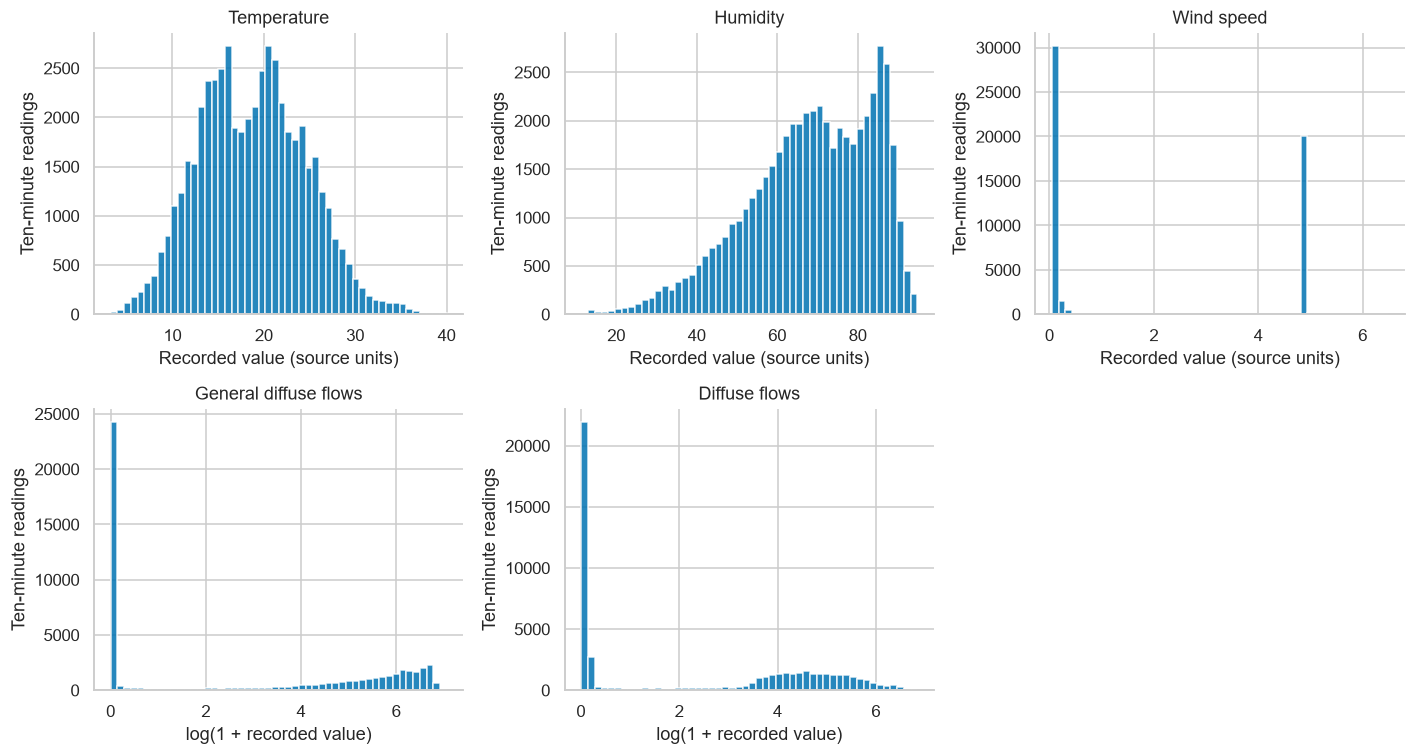

In [3]:
weather_stats = df[WEATHER].describe(percentiles=[.05,.25,.50,.75,.95,.99]).T
weather_stats["iqr"] = weather_stats["75%"] - weather_stats["25%"]
weather_stats["skewness"] = df[WEATHER].skew()
weather_stats["excess_kurtosis"] = df[WEATHER].kurt()
save_table(weather_stats, "01_weather_descriptive_statistics")
display(weather_stats[["count","mean","std","min","50%","max"]].round(3))
display(weather_stats[["5%","25%","75%","95%","99%","iqr","skewness","excess_kurtosis"]].round(3))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, weather in zip(axes.flat, WEATHER):
    values = df[weather]
    is_flow = "flows" in weather
    shown = np.log1p(values) if is_flow else values
    ax.hist(shown, bins=50, color="#0072B2", edgecolor="white", alpha=.85)
    ax.set(title=W_LABELS[weather], ylabel="Ten-minute readings",
           xlabel="log(1 + recorded value)" if is_flow else "Recorded value (source units)")
axes.flat[-1].axis("off")
show_figure(fig, "01_weather_distributions")

### Interpretation: Weather Distributions
- Temperature ranges from **3.247 to 40.010**, with a median of **18.780**.
- Humidity ranges from **11.340 to 94.800**, with a median of **69.860**.
- Wind speed has a median of **0.086**, but its 75th percentile is **4.915**. A single mean hides this strong separation.
- The flow fields span wide ranges: general diffuse flows reaches **1,163**, while diffuse flows reaches **936**. Many readings are near the lower end.

The flow histograms' transformed x-axes must be explained during a defence: equal horizontal distances represent differences in log(1 + value), not equal changes in the original measurement.

A clustered distribution is a reason to investigate, not proof of sensor failure. No values are removed or replaced here.

## 4. Daily and Monthly Weather Patterns
Plot daily means separately for each field, preserving its own scale. A monthly table provides exact averages for the report.

Weather and demand both change over time. This shared structure can create a strong raw association even when comparisons within similar calendar conditions are weaker.

,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows
month,,,,,
1,12.743,68.294,0.708,103.343,68.687
2,12.644,66.551,1.096,125.769,91.628
3,14.580,71.100,1.006,181.091,93.984
4,16.444,75.243,0.224,159.399,84.303
5,20.294,68.712,2.298,273.666,123.048
6,22.143,68.643,1.567,279.645,103.755
7,27.204,57.509,4.631,293.841,75.207
8,25.748,66.051,4.535,228.031,67.400
9,22.638,66.853,2.946,201.210,48.628


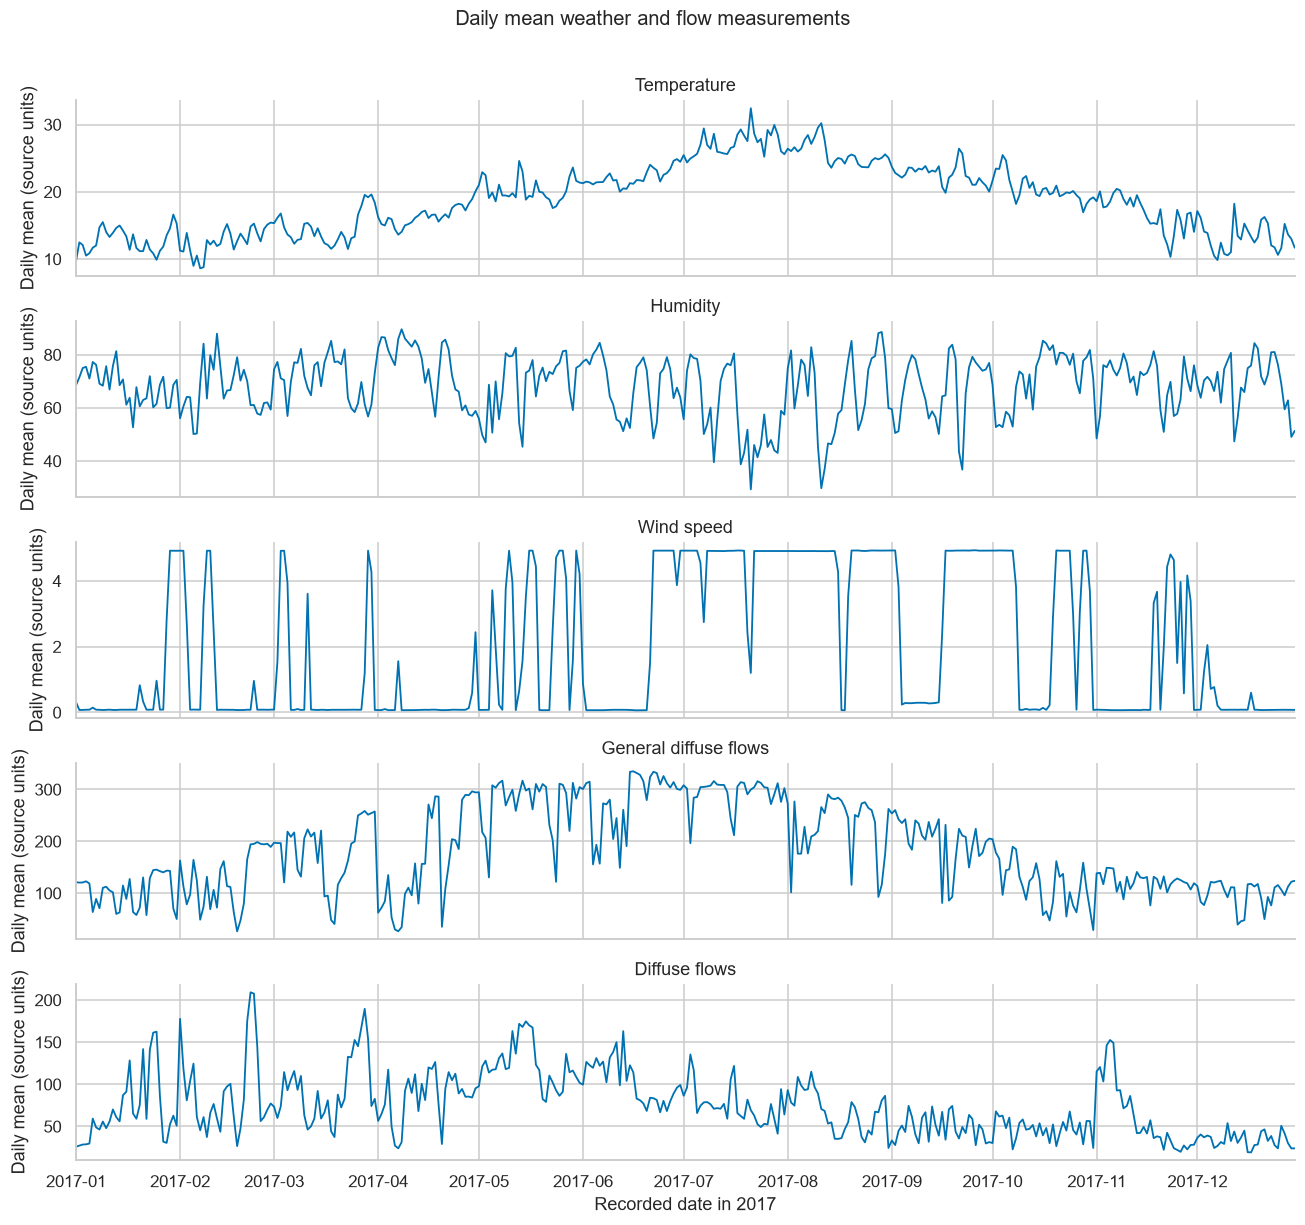

In [4]:
monthly_weather = df.groupby("month")[WEATHER].mean()
save_table(monthly_weather, "02_monthly_weather_means")
save_table(daily[WEATHER], "03_daily_weather_means")
display(monthly_weather.round(3))
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for ax, weather in zip(axes, WEATHER):
    ax.plot(daily.index, daily[weather], color="#0072B2", linewidth=1.2)
    ax.set(title=W_LABELS[weather], ylabel="Daily mean (source units)")
axes[-1].set(xlabel="Recorded date in 2017", xlim=(daily.index.min(), daily.index.max()))
fig.suptitle("Daily mean weather and flow measurements", y=1.01)
show_figure(fig, "02_daily_weather_patterns")

### Interpretation: Calendar Structure in Weather
Monthly mean temperature is approximately **12.74 in January** and **27.20 in July**. July also had the highest combined monthly demand in Notebook 02.

Monthly mean wind speed varies markedly: approximately **0.22 in April**, **4.63 in July**, and **0.25 in December**. Its time pattern makes it especially important to examine whether a raw wind–demand relationship overlaps with the month pattern.

These are observations from one year. We cannot infer stable annual weather cycles, sensor correctness, or causal weather effects from the monthly averages alone.

## 5. Average Hourly Profiles
Compare mean weather/flow measurements and combined demand by recorded hour. Each panel uses its own y-axis and does not imply a common physical scale.

This helps identify shared time-of-day structure. Comparing average profiles is not a substitute for analysing the matching individual readings.

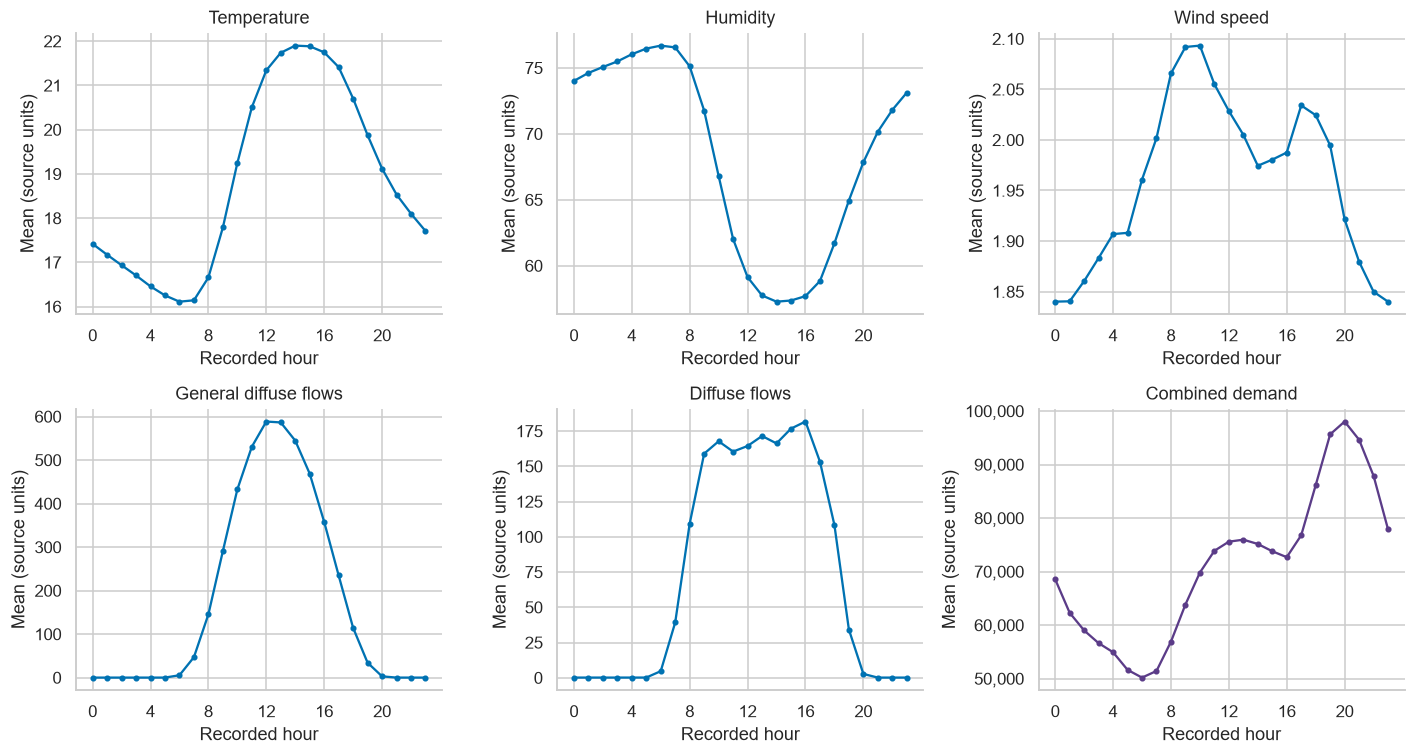

In [5]:
hourly = df.groupby("hour")[ALL_VALUES].mean().reindex(range(24))
save_table(hourly, "04_hourly_weather_and_demand_means")
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, variable in zip(axes.flat, WEATHER + ["total"]):
    label = "Combined demand" if variable == "total" else W_LABELS[variable]
    ax.plot(hourly.index, hourly[variable], marker="o", markersize=3,
            color=COLORS["total"] if variable == "total" else "#0072B2")
    ax.set(title=label, xlabel="Recorded hour", ylabel="Mean (source units)", xticks=range(0,24,4))
    if variable == "total":
        demand_axis(ax)
show_figure(fig, "03_hourly_weather_and_demand_profiles")

### Interpretation: Different Daily Timing
The flow measurements show a daytime rise, while the combined demand profile reaches its highest hourly mean during **20:00–20:50**.

Different timing can weaken a simultaneous correlation even if the variables share some daily or monthly structure. We should not interpret a small all-hours correlation as proof that the variable is irrelevant under every condition.

We keep the flow names supplied by the dataset and do not infer a verified solar measurement definition from these profiles alone.

## 6. Correlations Among Weather Variables and With Demand
Pearson correlation describes linear co-movement. Spearman correlation compares ranks and can reveal monotonic association even when the relationship is not a straight line.

First inspect relationships among the weather fields. Then compare each weather variable with the three zone readings and their combined value.

The same colour range, −1 to +1, is used across correlation panels. We do not report significance tests that treat consecutive ten-minute observations as independent samples.

,zone1,zone2,zone3,total
temperature,0.440,0.382,0.490,0.488
humidity,-0.287,-0.295,-0.233,-0.299
wind_speed,0.167,0.146,0.279,0.222
general_diffuse_flows,0.188,0.157,0.063,0.150
diffuse_flows,0.080,0.045,-0.039,0.032


,zone1,zone2,zone3,total
temperature,0.433,0.379,0.436,0.469
humidity,-0.300,-0.309,-0.212,-0.306
wind_speed,0.107,0.087,0.079,0.107
general_diffuse_flows,0.261,0.242,0.085,0.227
diffuse_flows,0.125,0.097,-0.021,0.082


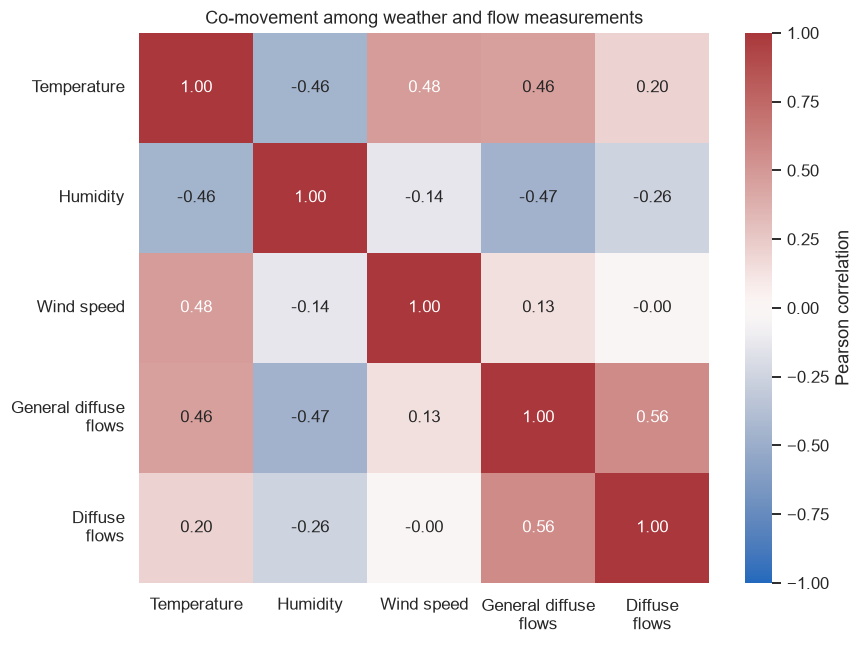

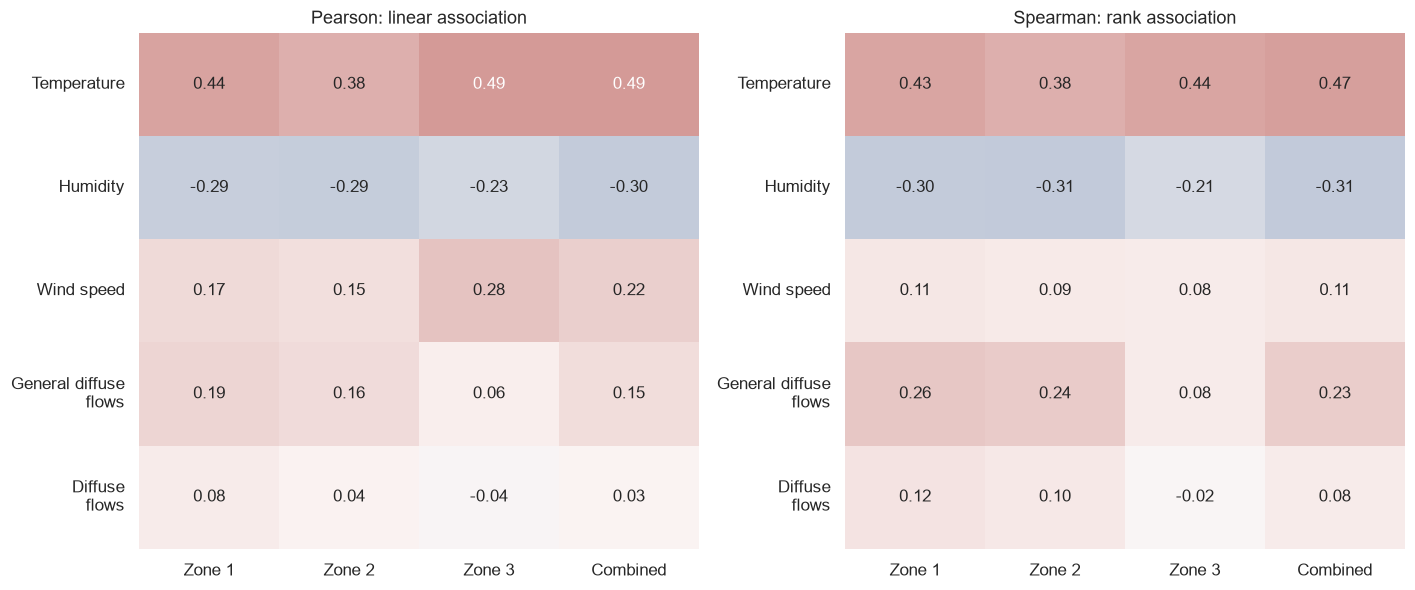

In [6]:
weather_corr = df[WEATHER].corr()
pearson = df[ALL_VALUES].corr().loc[WEATHER, SERIES]
spearman = df[ALL_VALUES].corr(method="spearman").loc[WEATHER, SERIES]
save_table(weather_corr, "05_weather_pearson_correlations")
save_table(pearson, "06_weather_demand_pearson")
save_table(spearman, "07_weather_demand_spearman")
display(pearson.round(3))
display(spearman.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(weather_corr, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            xticklabels=SHORT_LABELS, yticklabels=SHORT_LABELS,
            cbar_kws={"label": "Pearson correlation"})
ax.set_title("Co-movement among weather and flow measurements")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
show_figure(fig, "04_weather_correlation_matrix")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, matrix, title in [(axes[0], pearson, "Pearson: linear association"),
                           (axes[1], spearman, "Spearman: rank association")]:
    sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                xticklabels=[LABELS[s] for s in SERIES], yticklabels=SHORT_LABELS,
                cbar=False)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
show_figure(fig, "05_raw_weather_demand_correlations")

### Interpretation: Raw Associations
For combined demand, Pearson correlations are approximately:
- **Temperature: +0.488**.
- **Humidity: −0.299**.
- **Wind speed: +0.222**.
- **General diffuse flows: +0.150**.
- **Diffuse flows: +0.032**.

Temperature has the largest absolute raw Pearson correlation with combined demand among these five fields. This is not a ranking of causal effects or proven forecasting value.

Wind's Spearman correlation with combined demand is only about **+0.107**, compared with Pearson's **+0.222**. Its clustered readings and shared calendar pattern warrant closer inspection.

Weather variables also overlap: temperature and humidity correlate at approximately **−0.460**, while temperature and wind correlate at approximately **+0.477**. A separate pairwise correlation does not isolate one variable's contribution.

## 7. Plot the Individual Weather–Demand Relationships
Hexagonal density plots use every observation. Each hexagon's colour represents the number of matching readings, with logarithmic colour scaling so that both dense and sparse areas can be seen.

Each panel has its own count colour scale. Colours therefore indicate density within that panel and should not be compared as equal counts across different panels.

We show all three zones rather than assuming that the combined relationship describes every zone equally.

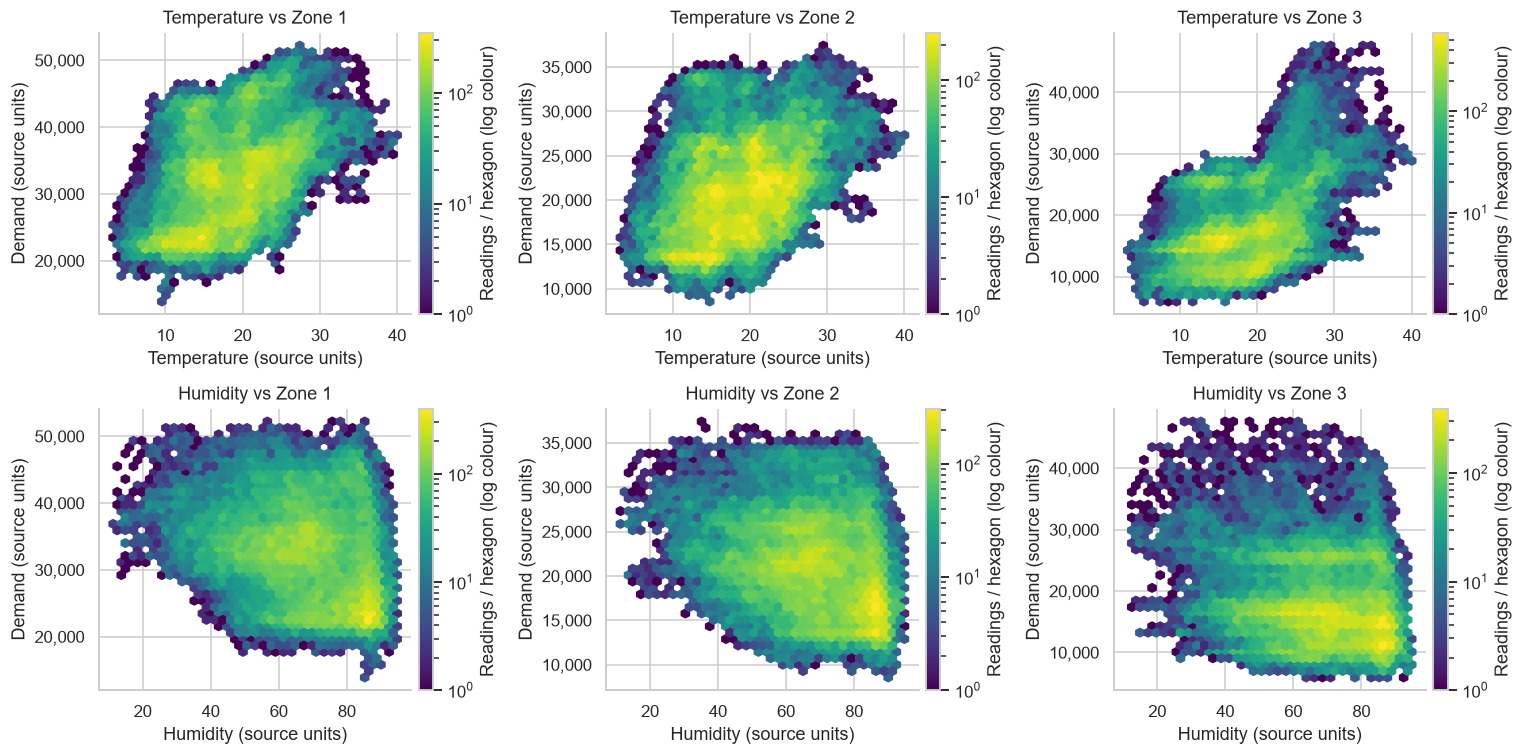

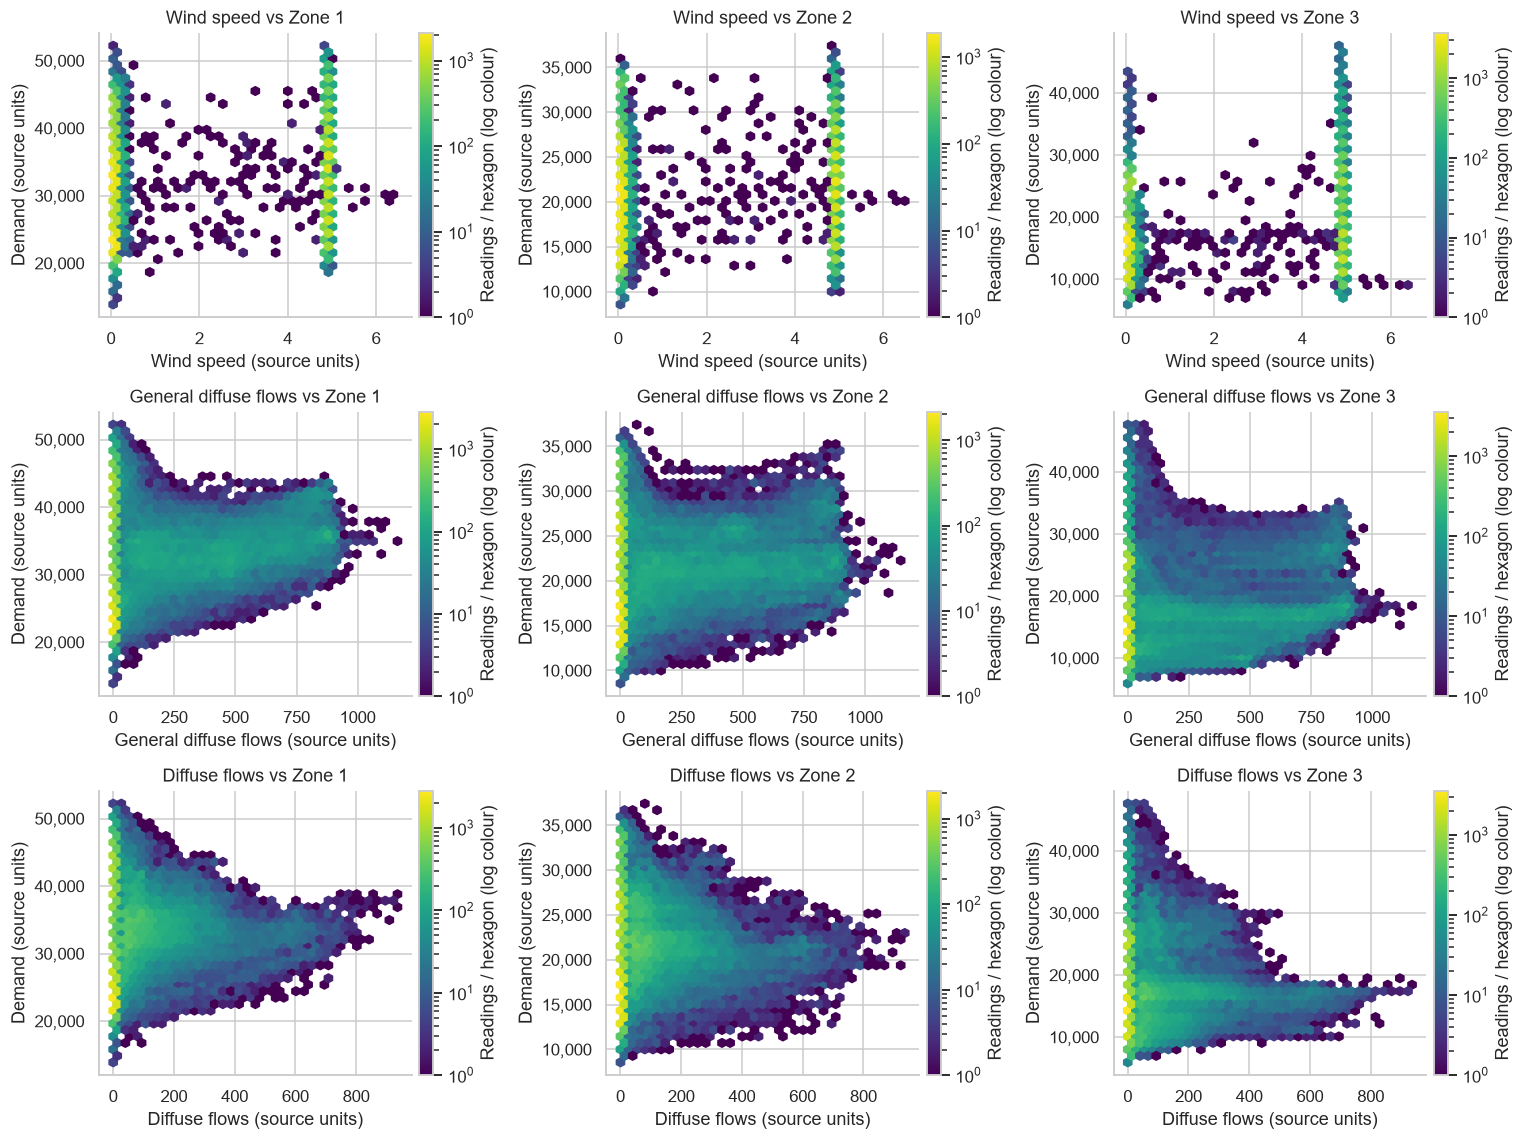

In [7]:
def density_panels(weather_fields, figure_name):
    fig, axes = plt.subplots(len(weather_fields), 3,
                             figsize=(14, 3.5 * len(weather_fields)), squeeze=False)
    for row, weather in enumerate(weather_fields):
        for col, zone in enumerate(ZONES):
            ax = axes[row, col]
            density = ax.hexbin(df[weather], df[zone], gridsize=35,
                                mincnt=1, bins="log", cmap="viridis")
            fig.colorbar(density, ax=ax, label="Readings / hexagon (log colour)", pad=.02)
            ax.set(title=f"{W_LABELS[weather]} vs {LABELS[zone]}",
                   xlabel=f"{W_LABELS[weather]} (source units)",
                   ylabel="Demand (source units)")
            demand_axis(ax)
    show_figure(fig, figure_name)

density_panels(["temperature", "humidity"], "06_temperature_humidity_density")
density_panels(["wind_speed", "general_diffuse_flows", "diffuse_flows"], "07_wind_flow_density")

### Interpretation: Overlap, Curvature, and Zone Differences
The plots show broad demand ranges at similar weather readings. Weather alone therefore does not determine the demand level.

Wind readings occupy narrow clusters, while the flow plots have a dense low-value region and a longer upper range. A fitted straight line could hide these features.

Curves or clusters in these plots can also arise from mixing hours and months. We next summarise the shapes, then compare relationships within calendar groups before drawing modelling conclusions.

## 8. Quantile-Binned Relationships
Divide each weather field into approximately equal-count bins. Repeated values can prevent exactly equal counts or reduce the number of distinct bins, so we keep and report the actual counts.

For every bin, save its weather range, mean weather value, mean zone demand, and combined-demand mean, median, and quartiles. The figures focus on temperature and humidity.

These are grouped descriptive curves, not fitted response functions. The shaded bands show the middle 50% of individual combined-demand readings in each bin, not confidence intervals.

Temperature: 10 bins; 5,215–5,264 readings per bin
Humidity: 10 bins; 5,102–5,289 readings per bin
Wind speed: 10 bins; 4,278–6,202 readings per bin
General diffuse flows: 10 bins; 4,347–6,044 readings per bin
Diffuse flows: 10 bins; 4,662–5,699 readings per bin


,readings,weather_min,weather_mean,weather_max,demand_mean,demand_median,demand_p25,demand_p75,zone1_mean,zone2_mean,zone3_mean
quantile_bin,,,,,,,,,,,
0,5251,3.25,9.34,11.43,58209.32,52759.31,49478.89,63645.55,26507.45,17671.09,14030.77
1,5264,11.44,12.63,13.62,65699.41,62413.53,51400.51,77653.09,30062.03,19743.81,15893.57
2,5215,13.63,14.42,15.22,67087.63,66641.27,52557.36,77789.60,30815.71,19882.81,16389.11
3,5249,15.23,15.98,16.76,66794.16,66835.04,54839.85,73621.12,30789.56,20226.13,15778.47
4,5234,16.77,17.80,18.78,66975.43,66067.59,55488.67,74670.27,31142.31,20338.82,15494.31
5,5252,18.79,19.66,20.43,69317.26,67867.96,55443.72,82706.79,32161.66,20994.79,16160.81
6,5244,20.44,21.14,21.91,72058.21,70184.64,61294.06,79625.67,33438.14,21429.53,17190.55
7,5246,21.92,22.92,23.97,75260.92,72800.12,67104.25,81816.44,34650.11,21705.86,18904.96
8,5225,23.98,25.11,26.38,79962.78,75271.83,68897.28,89296.12,35496.31,22641.03,21825.44


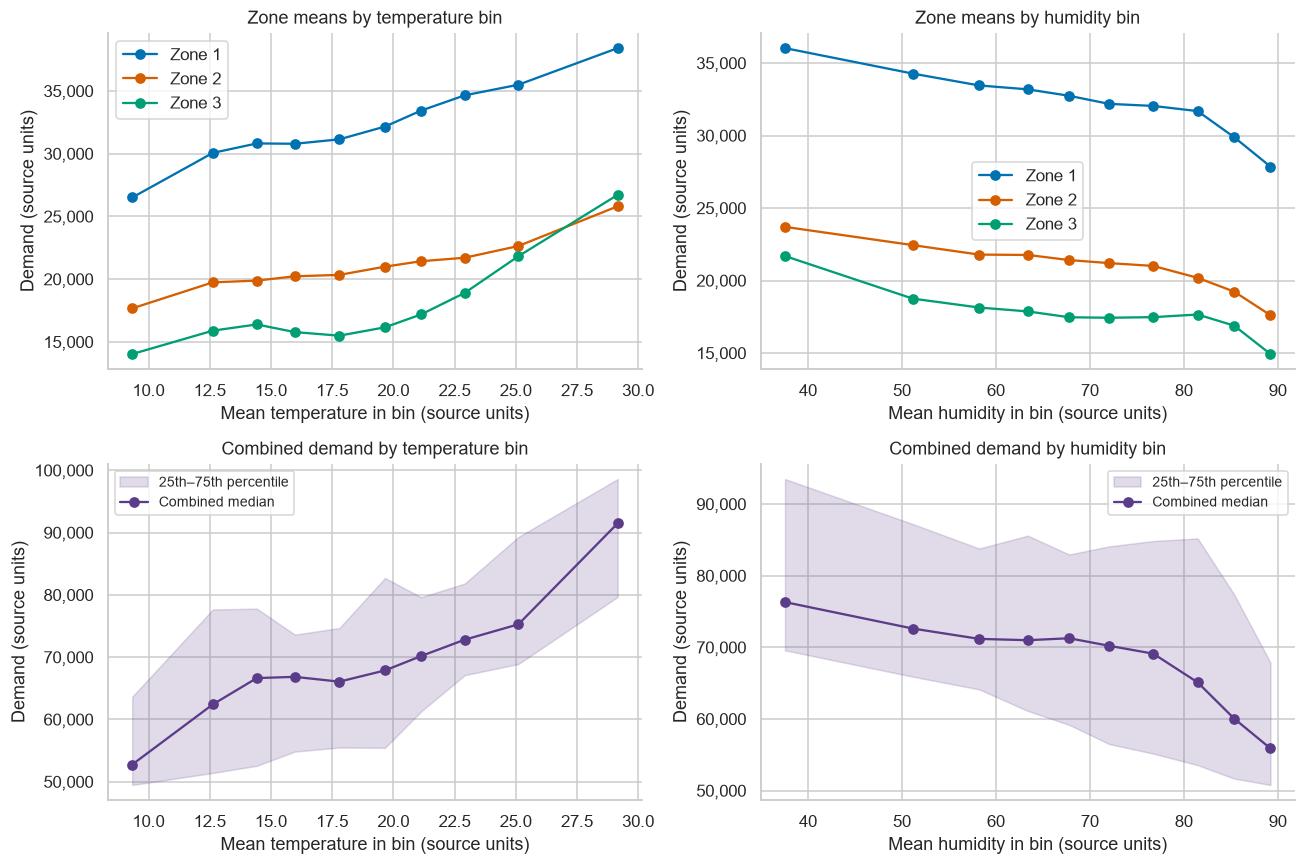

In [8]:
def quantile_summary(data, weather, target="total", bins=10):
    bin_id = pd.qcut(data[weather], q=bins, labels=False, duplicates="drop")
    grouped = data.groupby(bin_id, observed=True)
    summary = grouped.agg(
        readings=(weather, "size"), weather_min=(weather, "min"),
        weather_mean=(weather, "mean"), weather_max=(weather, "max"),
        demand_mean=(target, "mean"), demand_median=(target, "median"),
        demand_p25=(target, lambda x: x.quantile(.25)),
        demand_p75=(target, lambda x: x.quantile(.75)),
    )
    summary.index.name = "quantile_bin"
    for zone in ZONES:
        if zone in data.columns:
            summary[f"{zone}_mean"] = grouped[zone].mean()
    assert summary["readings"].sum() == len(data)
    return summary

binned = {w: quantile_summary(df, w) for w in WEATHER}
for weather, table in binned.items():
    save_table(table, f"08_binned_{weather}")
    print(f"{W_LABELS[weather]}: {len(table)} bins; {table['readings'].min():,}–{table['readings'].max():,} readings per bin")
display(binned["temperature"].round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, weather in enumerate(["temperature", "humidity"]):
    table = binned[weather]
    for zone in ZONES:
        axes[0,col].plot(table["weather_mean"], table[f"{zone}_mean"], marker="o",
                         color=COLORS[zone], label=LABELS[zone])
    axes[0,col].set(title=f"Zone means by {W_LABELS[weather].lower()} bin")
    axes[0,col].legend()
    axes[1,col].fill_between(table["weather_mean"], table["demand_p25"], table["demand_p75"],
                             color=COLORS["total"], alpha=.18, label="25th–75th percentile")
    axes[1,col].plot(table["weather_mean"], table["demand_median"], marker="o",
                     color=COLORS["total"], label="Combined median")
    axes[1,col].set(title=f"Combined demand by {W_LABELS[weather].lower()} bin")
    axes[1,col].legend(fontsize=9)
    for ax in axes[:,col]:
        ax.set(xlabel=f"Mean {W_LABELS[weather].lower()} in bin (source units)", ylabel="Demand (source units)")
        demand_axis(ax)
show_figure(fig, "08_binned_temperature_humidity")

### Interpretation: Binned Shapes
The grouped temperature curves generally rise across the observed range, while the humidity curves generally decline. Their shapes and spreads are more informative than one correlation coefficient alone.

The bands overlap substantially, showing that weather categories still contain a wide range of demand. We should not treat the bin average as an exact prediction for every reading in that bin.

Quantile bins have unequal widths on the weather axis. Connecting their means helps display the pattern but does not imply that the relationship was observed uniformly between those points.

## 9. Temperature Associations by Part of the Day
Compare binned mean combined demand for night, morning, afternoon, and evening. Use the same temperature-bin boundaries across all four day parts.

The saved table includes subgroup counts. For the plot, omit subgroups with fewer than 100 readings to reduce visual emphasis on sparse combinations. This is a descriptive display rule, not a statistical significance threshold; adjacent readings remain dependent.

day_part,Night (00–05),Morning (06–11),Afternoon (12–17),Evening (18–23)
temperature_bin,,,,
0,2163,2060,140,888
1,1644,1479,548,1593
2,1466,1206,1060,1483
3,1237,1203,1628,1181
4,1543,1178,1307,1206
5,1565,1462,764,1461
6,1269,1171,1482,1322
7,985,1298,1627,1336
8,995,1207,1600,1423


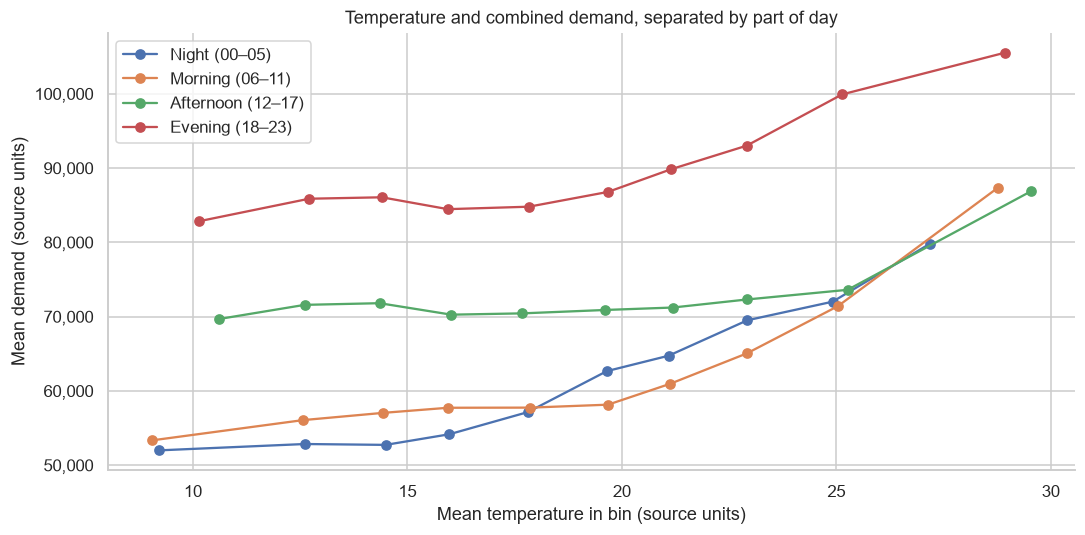

In [9]:
temperature_bins = pd.qcut(df["temperature"], q=10, labels=False, duplicates="drop")
daypart_bins = df.assign(temperature_bin=temperature_bins).groupby(
    ["day_part", "temperature_bin"], observed=True
).agg(readings=("total","size"), temperature_mean=("temperature","mean"), demand_mean=("total","mean"))
save_table(daypart_bins, "09_temperature_by_daypart_bins")
display(daypart_bins["readings"].unstack("day_part").fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(10, 5))
for part in df["day_part"].cat.categories:
    table = daypart_bins.xs(part, level="day_part")
    table = table.loc[table["readings"].ge(100)]
    ax.plot(table["temperature_mean"], table["demand_mean"], marker="o", label=part)
ax.set(title="Temperature and combined demand, separated by part of day",
       xlabel="Mean temperature in bin (source units)", ylabel="Mean demand (source units)")
ax.legend()
demand_axis(ax)
show_figure(fig, "09_temperature_daypart_comparison")

### Interpretation: Time Categories Matter
The day-part curves occupy different demand levels. Similar temperature values can coincide with very different demand depending on the time of day.

Separating day parts improves the description but does not fully account for time. The categories span six hours, and their observations still come from different months and weekdays. The next comparison uses narrower month-and-hour groups.

## 10. Compare Deviations Within the Same Month and Hour
For every weather variable and demand series, subtract the mean of its month-and-hour group:

**Deviation = recorded value − mean value for the same month and hour.**

For example, a July 20:10 reading is compared with the average of all available July readings during 20:00–20:50. We then correlate weather deviations with demand deviations.

This removes differences between the 288 month-by-hour group means. It is a descriptive calendar adjustment, not a causal effect estimate. It does not adjust for weekdays, holidays, all within-hour variation, or other weather variables. It can also remove genuine weather variation shared with month and hour.

The group means use the entire file solely for this retrospective analysis. They must not be reused as fitted forecasting preprocessing or training-derived features.

,zone1,zone2,zone3,total
temperature,0.043,0.023,0.133,0.080
humidity,-0.041,-0.047,-0.094,-0.074
wind_speed,-0.035,-0.060,-0.014,-0.046
general_diffuse_flows,0.004,-0.014,0.041,0.011
diffuse_flows,-0.012,-0.012,-0.047,-0.028


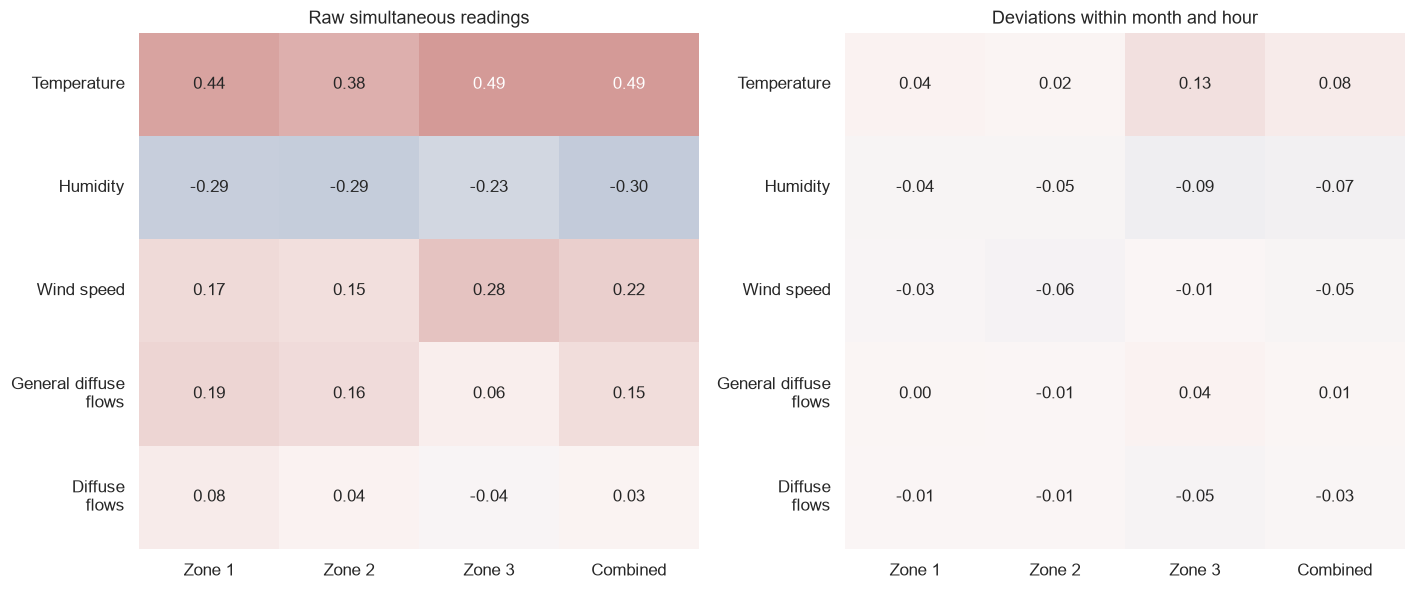

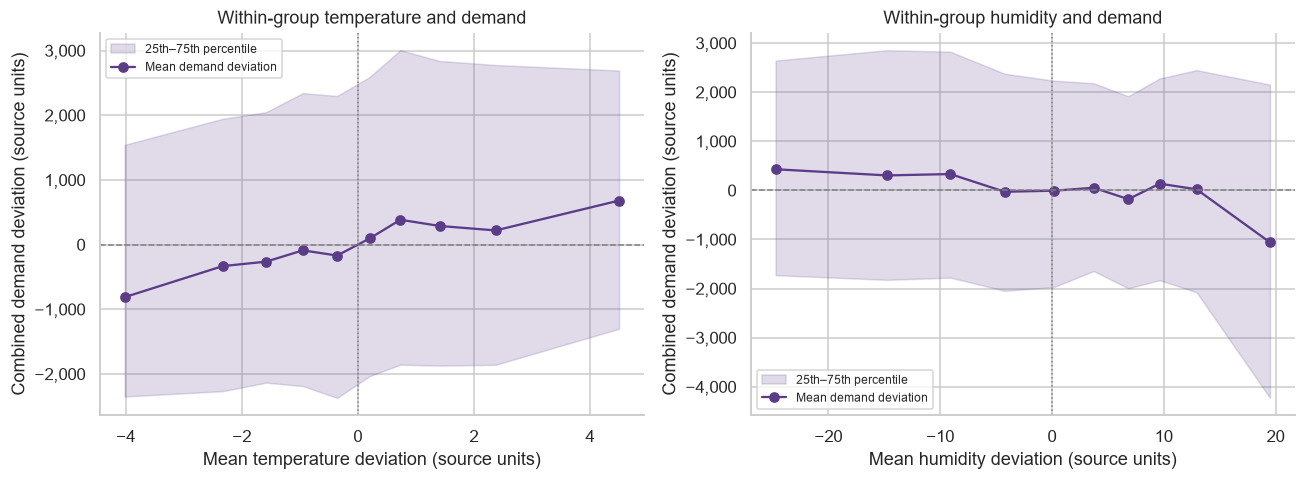

In [10]:
calendar_means = df.groupby(["month","hour"])[ALL_VALUES].transform("mean")
deviations = df[ALL_VALUES] - calendar_means
group_check = deviations.groupby([df["month"], df["hour"]]).mean()
assert np.allclose(group_check.to_numpy(), 0, atol=1e-8)
adjusted_corr = deviations.corr().loc[WEATHER, SERIES]
save_table(adjusted_corr, "10_within_month_hour_pearson")
save_table(df.groupby(["month","hour"]).size().rename("readings"), "11_calendar_group_counts")
display(adjusted_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, matrix, title in [(axes[0], pearson, "Raw simultaneous readings"),
                           (axes[1], adjusted_corr, "Deviations within month and hour")]:
    sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                xticklabels=[LABELS[s] for s in SERIES], yticklabels=SHORT_LABELS, cbar=False)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
show_figure(fig, "10_raw_vs_calendar_adjusted_correlations")

adjusted_bins = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, weather in zip(axes, ["temperature", "humidity"]):
    table = quantile_summary(deviations, weather)
    adjusted_bins[weather] = table
    save_table(table, f"12_deviation_bins_{weather}")
    ax.fill_between(table["weather_mean"], table["demand_p25"], table["demand_p75"], color=COLORS["total"], alpha=.18, label="25th–75th percentile")
    ax.plot(table["weather_mean"], table["demand_mean"], marker="o", color=COLORS["total"], label="Mean demand deviation")
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.axvline(0, color="grey", linestyle=":", linewidth=1)
    ax.set(title=f"Within-group {W_LABELS[weather].lower()} and demand",
           xlabel=f"Mean {W_LABELS[weather].lower()} deviation (source units)",
           ylabel="Combined demand deviation (source units)")
    ax.legend(fontsize=8)
    demand_axis(ax)
show_figure(fig, "11_calendar_deviation_binned_relationships")

### Interpretation: Raw Relationships Become Much Weaker
For combined demand, raw versus within-month/hour Pearson correlations are approximately:
- Temperature: **+0.488 → +0.080**.
- Humidity: **−0.299 → −0.074**.
- Wind speed: **+0.222 → −0.046**.
- General diffuse flows: **+0.150 → +0.011**.
- Diffuse flows: **+0.032 → −0.028**.

Much of the raw co-movement overlaps with differences between calendar groups. The weak adjusted correlations do not prove that weather has no effect or cannot improve a forecast. This calculation addresses only the remaining linear co-movement after one particular time adjustment.

Zone 3 retains a somewhat larger temperature-deviation correlation (**+0.133**) than Zone 1 (**+0.043**) or Zone 2 (**+0.023**). That is a descriptive zone difference to evaluate later, not evidence of a causal sensitivity.

## 11. Sensitivity to Time Aggregation
Compare correlations from ten-minute readings with correlations from daily means. The daily calculation uses 364 paired daily averages, not the original 52,416 readings.

Aggregation removes some within-day variation and can emphasise broader calendar structure. It changes the question being answered. A larger daily correlation does not establish stronger causal evidence or better ten-minute forecasts.

,ten_minute_raw,daily_means,within_month_hour
temperature,0.488,0.732,0.080
humidity,-0.299,-0.290,-0.074
wind_speed,0.222,0.489,-0.046
general_diffuse_flows,0.150,0.554,0.011
diffuse_flows,0.032,0.085,-0.028


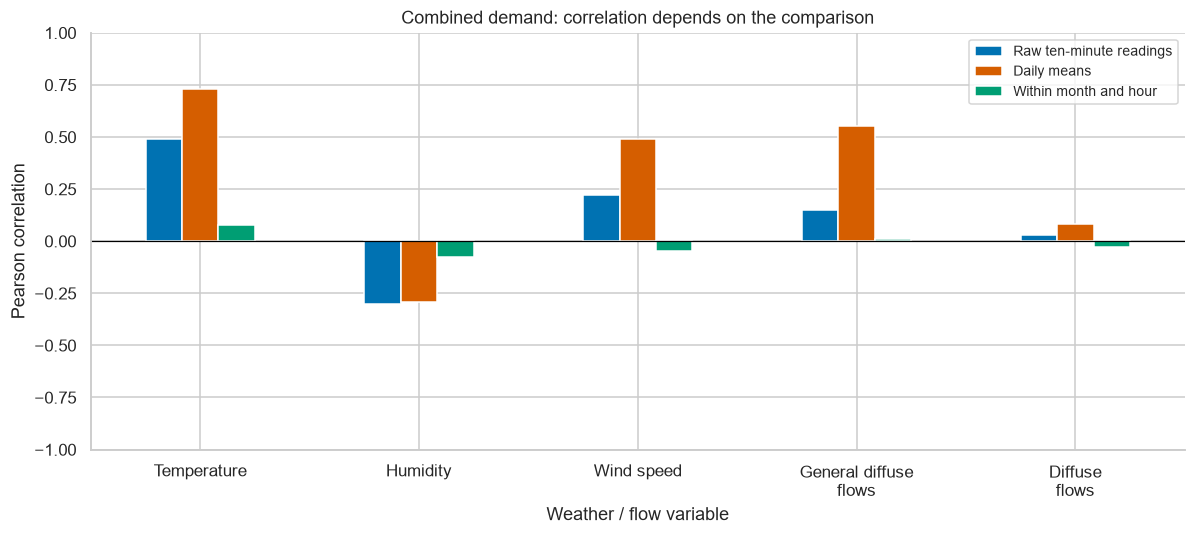

In [11]:
daily_corr = daily.corr().loc[WEATHER, SERIES]
save_table(daily_corr, "13_daily_mean_weather_demand_correlations")
sensitivity = pd.DataFrame({"ten_minute_raw": pearson["total"],
                            "daily_means": daily_corr["total"],
                            "within_month_hour": adjusted_corr["total"]})
save_table(sensitivity, "14_combined_correlation_sensitivity")
display(sensitivity.round(3))
fig, ax = plt.subplots(figsize=(11, 5))
sensitivity.set_axis(SHORT_LABELS).plot.bar(ax=ax, rot=0,
    color=["#0072B2", "#D55E00", "#009E73"])
ax.axhline(0, color="black", linewidth=.8)
ax.set(title="Combined demand: correlation depends on the comparison",
       xlabel="Weather / flow variable", ylabel="Pearson correlation", ylim=(-1,1))
ax.legend(handles=ax.containers, labels=["Raw ten-minute readings", "Daily means", "Within month and hour"], fontsize=9)
show_figure(fig, "12_aggregation_sensitivity")

### Interpretation: Different Aggregations Answer Different Questions
Temperature's combined-demand correlation is approximately **+0.488** for ten-minute readings and **+0.732** for daily means. General diffuse flows rises from approximately **+0.150** to **+0.554** under daily aggregation.

These larger daily correlations describe day-to-day co-movement, including broad monthly differences. They do not contradict the smaller within-month/hour correlations, which compare a different part of the variation.

The daily observations can still be serially dependent. We do not treat aggregation as a guarantee of independent samples.

## 12. Wind-Speed Diagnostics
Examine the two prominent wind ranges more closely and report their monthly composition.

The four bands below are descriptive ranges in source units, not validated physical regimes or sensor-fault classes. They partition all observations:
- Below 0.1.
- At least 0.1 and below 4.
- From 4 through 6, inclusive.
- Above 6.

The zoomed histograms show only their named ranges; the monthly chart includes all readings. We also save frequently recorded values and the longest identical run.

Longest identical wind run: 7 readings, spanning 60 minutes from first to last.


,readings,percentage
Below 0.1,29882,57.01
0.1 to below 4,2287,4.36
4 through 6,20244,38.62
Above 6,3,0.01


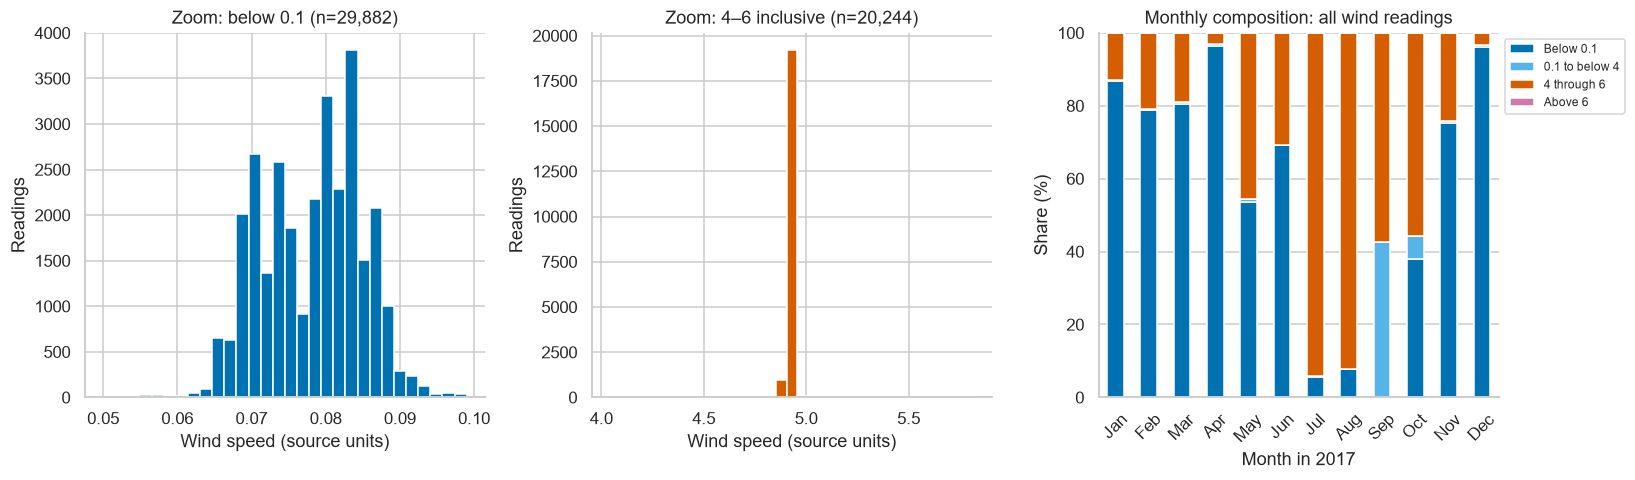

In [12]:
WIND_BANDS = ["Below 0.1", "0.1 to below 4", "4 through 6", "Above 6"]
wind_band = np.select(
    [df["wind_speed"].lt(.1), df["wind_speed"].lt(4), df["wind_speed"].le(6)],
    WIND_BANDS[:3], default=WIND_BANDS[3]
)
wind_overall = pd.Series(wind_band).value_counts().reindex(WIND_BANDS, fill_value=0).rename("readings").to_frame()
wind_overall["percentage"] = wind_overall["readings"] / len(df) * 100
wind_monthly = pd.crosstab(df["month"], wind_band).reindex(columns=WIND_BANDS, fill_value=0)
wind_monthly_pct = wind_monthly.div(wind_monthly.sum(axis=1), axis=0) * 100
assert wind_overall["readings"].sum() == len(df)
assert np.allclose(wind_monthly_pct.sum(axis=1), 100)
save_table(wind_overall, "15_wind_band_overall")
save_table(wind_monthly_pct, "16_wind_band_monthly_percentages")
save_table(df["wind_speed"].value_counts().head(15).rename("readings"), "17_most_frequent_wind_values")
display(wind_overall.round(2))
run_groups = df["wind_speed"].ne(df["wind_speed"].shift()).cumsum()
longest_wind_run = int(df.groupby(run_groups).size().max())
print(f"Longest identical wind run: {longest_wind_run} readings, spanning {(longest_wind_run-1)*10} minutes from first to last.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
low = df.loc[df["wind_speed"].lt(.1), "wind_speed"]
high = df.loc[df["wind_speed"].between(4,6), "wind_speed"]
axes[0].hist(low, bins=30, color="#0072B2", edgecolor="white")
axes[0].set(title=f"Zoom: below 0.1 (n={len(low):,})", xlabel="Wind speed (source units)", ylabel="Readings")
axes[1].hist(high, bins=35, color="#D55E00", edgecolor="white")
axes[1].set(title=f"Zoom: 4–6 inclusive (n={len(high):,})", xlabel="Wind speed (source units)", ylabel="Readings")
wind_monthly_pct.set_axis(MONTHS).plot.bar(stacked=True, ax=axes[2], rot=45,
    color=["#0072B2", "#56B4E9", "#D55E00", "#CC79A7"])
axes[2].set(title="Monthly composition: all wind readings", xlabel="Month in 2017", ylabel="Share (%)", ylim=(0,100))
axes[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1,1))
show_figure(fig, "13_wind_distribution_diagnostics")

### Interpretation: Wind Requires Cautious Use
Approximately **57.01%** of wind readings are below 0.1 and **38.62%** are between 4 and 6, inclusive. Together those two ranges contain about **95.63%** of the observations.

Their monthly composition changes sharply. Approximately **94.11%** of July readings and **92.20%** of August readings lie in the 4–6 range. The longest identical wind run is seven readings, spanning **60 minutes** from first to last.

These calculations correct the older approximate wind note in the project configuration, which described 75% below 0.1. We use measured percentages, not that approximation.

Neither the distribution nor repeated values prove sensor failure. We retain wind speed, document the pattern, and will assess its incremental forecasting value on training/validation data.

## 13. Flow Measurements: Low Values and Overlapping Information
Inspect how the two flow measurements move together, using a log(1 + value) density plot to show their wide ranges.

We also report the proportion of readings at or below 1 source unit. This cutoff describes concentration near the lower end; it is not a verified daylight threshold, a physical zero, or a reason to remove values.

,minimum,median,maximum,at_or_below_1_pct,exact_zero_readings
general_diffuse_flows,0.004,5.036,1163.0,47.941,0
diffuse_flows,0.011,4.456,936.0,48.022,0


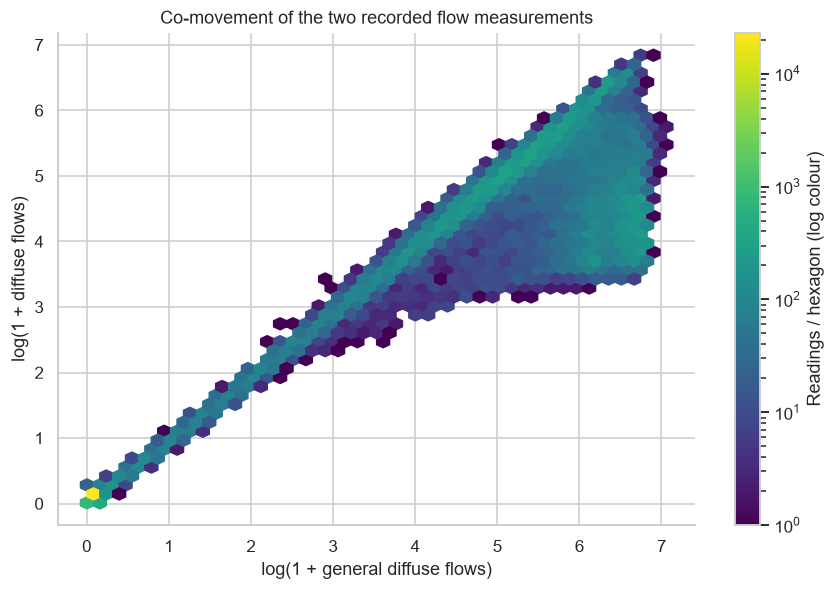

In [13]:
FLOW = ["general_diffuse_flows", "diffuse_flows"]
flow_summary = pd.DataFrame({
    "minimum": df[FLOW].min(), "median": df[FLOW].median(), "maximum": df[FLOW].max(),
    "at_or_below_1_pct": df[FLOW].le(1).mean() * 100,
    "exact_zero_readings": df[FLOW].eq(0).sum(),
})
save_table(flow_summary, "18_flow_low_value_summary")
display(flow_summary.round(3))
fig, ax = plt.subplots(figsize=(8, 5.5))
hx = ax.hexbin(np.log1p(df[FLOW[0]]), np.log1p(df[FLOW[1]]),
                gridsize=45, bins="log", mincnt=1, cmap="viridis")
fig.colorbar(hx, ax=ax, label="Readings / hexagon (log colour)")
ax.set(title="Co-movement of the two recorded flow measurements",
       xlabel="log(1 + general diffuse flows)", ylabel="log(1 + diffuse flows)")
show_figure(fig, "14_flow_measurement_relationship")

### Interpretation: Flow Fields Are Related but Not Interchangeable
Approximately **47.94%** of general diffuse flow readings and **48.02%** of diffuse flow readings are at or below 1 source unit. Neither field contains exact zero readings in this file.

The raw Pearson correlation between the two fields is approximately **+0.565**. They contain overlapping information, but are not interchangeable measurements.

Their raw simultaneous correlations with combined demand are comparatively small, especially for diffuse flows. We should assess their contribution beyond calendar features rather than selecting or discarding them using only one correlation.

## 14. What Would Be Available at Forecast Time?
Observed weather at the future target timestamp is not automatically available at the forecast origin. Using it without explanation would make a practical forecast evaluation optimistic.

The table below separates information availability from an apparent historical relationship. The forecast horizon will determine which lags can be used.

In [14]:
availability = pd.DataFrame([
    ("Calendar fields", "Target hour, weekday, month", "Known ahead", "Use the target calendar without fitting on later outcomes."),
    ("Past demand", "Earlier zone readings", "Known only through forecast origin", "Align each lag with the agreed horizon; never use later observations."),
    ("Past weather", "Earlier weather/flow readings", "Known only through forecast origin", "Lag or aggregate only information already observed."),
    ("Future observed weather", "Recorded weather at target time", "Not generally known ahead", "Exclude from a practical forecast unless explicitly labelled as a perfect-weather scenario."),
    ("Weather forecasts", "Predictions issued before target time", "Potentially available if archived", "Require a separate source with issue times; none is provided in this dataset."),
    ("Calendar-adjusted deviations here", "Full-file month/hour averages", "Retrospective analysis only", "Do not reuse these full-file group means as forecasting preprocessing."),
], columns=["information", "example", "availability", "rule"])
save_table(availability, "19_forecast_information_availability", index=False)
with pd.option_context("display.max_colwidth", None):
    display(availability)

,information,example,availability,rule
0,Calendar fields,"Target hour, weekday, month",Known ahead,Use the target calendar without fitting on later outcomes.
1,Past demand,Earlier zone readings,Known only through forecast origin,Align each lag with the agreed horizon; never use later observations.
2,Past weather,Earlier weather/flow readings,Known only through forecast origin,Lag or aggregate only information already observed.
3,Future observed weather,Recorded weather at target time,Not generally known ahead,Exclude from a practical forecast unless explicitly labelled as a perfect-weather scenario.
4,Weather forecasts,Predictions issued before target time,Potentially available if archived,Require a separate source with issue times; none is provided in this dataset.
5,Calendar-adjusted deviations here,Full-file month/hour averages,Retrospective analysis only,Do not reuse these full-file group means as forecasting preprocessing.


### Interpretation: A Defensible Modelling Plan
Calendar features are a necessary baseline because demand has strong time patterns. Temperature and humidity remain candidates for nonlinear terms or time interactions, but their usefulness must be demonstrated beyond that baseline.

Wind and flow fields remain candidates rather than automatically approved predictors. Check their contribution with a chronological comparison of otherwise equivalent models, using information genuinely available at the forecast origin.

We have not established that weather improves forecasts. That requires an ablation comparison: a model with calendar/past-demand information versus the same setup with eligible weather information added, evaluated on the same horizon and target timestamps.

## 15. Save Findings and Verify Evidence Files
Save the main correlation comparisons and a figure index for team review. CSV tables preserve calculation precision; displayed figures are rounded only for readability.

The notebook performs no model fitting, saves no forecast thresholds, and does not overwrite the checked input dataset.

In [15]:
headlines = pd.Series({
    "observations": len(df), "observed_days": len(daily),
    "temperature_combined_raw_pearson": pearson.loc["temperature","total"],
    "temperature_combined_within_month_hour": adjusted_corr.loc["temperature","total"],
    "temperature_combined_daily_mean_pearson": daily_corr.loc["temperature","total"],
    "wind_combined_raw_pearson": pearson.loc["wind_speed","total"],
    "wind_combined_within_month_hour": adjusted_corr.loc["wind_speed","total"],
    "wind_below_0_1_pct": wind_overall.loc["Below 0.1","percentage"],
    "wind_4_through_6_pct": wind_overall.loc["4 through 6","percentage"],
}, name="value")
save_table(headlines, "20_headline_weather_findings")
display(headlines.round(4).to_frame())
figure_names = [
    "01_weather_distributions", "02_daily_weather_patterns", "03_hourly_weather_and_demand_profiles",
    "04_weather_correlation_matrix", "05_raw_weather_demand_correlations",
    "06_temperature_humidity_density", "07_wind_flow_density", "08_binned_temperature_humidity",
    "09_temperature_daypart_comparison", "10_raw_vs_calendar_adjusted_correlations",
    "11_calendar_deviation_binned_relationships", "12_aggregation_sensitivity",
    "13_wind_distribution_diagnostics", "14_flow_measurement_relationship",
]
purposes = [
    "Distribution shape of all five weather fields", "Daily weather changes during 2017",
    "Hourly weather and demand timing", "Overlap among weather fields", "Raw correlations by demand zone",
    "Individual temperature and humidity relationships", "Individual wind and flow relationships",
    "Binned demand levels and observed variability", "Temperature association by part of day",
    "Calendar structure versus within-group relationships", "Binned relationships after calendar adjustment",
    "Correlation sensitivity to aggregation", "Wind clusters and monthly composition",
    "Flow overlap and low-value concentration",
]
figure_index = pd.DataFrame({"figure": figure_names, "purpose": purposes})
save_table(figure_index, "21_figure_index", index=False)
for name in figure_names:
    for extension in ["png", "svg"]:
        assert (WX_FIGURES / f"{name}.{extension}").stat().st_size > 0
original = pd.read_parquet(clean_path)
pd.testing.assert_frame_equal(original, df[original.columns])
print(f"Completed: {len(figure_names)} figures, each saved as PNG and SVG.")
print("Cleaned input unchanged. No forecasting claims or fitted thresholds produced.")
print("Figures:", WX_FIGURES)
print("Tables :", WX_TABLES)

Completed: 14 figures, each saved as PNG and SVG.
Cleaned input unchanged. No forecasting claims or fitted thresholds produced.
Figures: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\figures\03_weather_relationships
Tables : C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\tables\03_weather_relationships


,value
observations,52416.0000
observed_days,364.0000
temperature_combined_raw_pearson,0.4882
temperature_combined_within_month_hour,0.0798
temperature_combined_daily_mean_pearson,0.7322
wind_combined_raw_pearson,0.2217
wind_combined_within_month_hour,-0.0463
wind_below_0_1_pct,57.0093
wind_4_through_6_pct,38.6218


## 16. Conclusions for the Team and Project Defence
1. **Raw weather associations exist.** Temperature has the largest absolute raw Pearson correlation with combined demand among the five recorded fields.
2. **Time structure matters.** The temperature correlation falls from about 0.49 to 0.08 when comparing deviations within the same month and hour. This is a descriptive adjustment, not proof of no weather effect.
3. **Zones differ.** Zone 3 retains a larger within-group temperature relationship than the other zones.
4. **Wind deserves further investigation.** Its readings cluster in narrow ranges whose proportions change by month. We do not label them as confirmed faults.
5. **Aggregation changes interpretation.** Correlations of daily means address broader day-to-day variation, while ten-minute and within-calendar comparisons answer different questions.
6. **Forecast availability is essential.** Observed future weather cannot silently be treated as known when issuing a forecast.

### Questions to prepare for the defence
- What does a correlation coefficient describe, and why is it not a causal effect?
- Why do Pearson and Spearman differ for wind?
- What does each density colour, curve, or shaded band represent?
- Why do raw, daily-mean, and within-calendar correlations differ?
- What was removed by the month-and-hour adjustment, and what was not?
- Would each proposed predictor actually be available at the forecast origin?

### Next notebook: Notebook 04 — Feature Engineering
Before building features, agree on the forecast horizon and whether forecasts are issued once per day or updated during the day. Then create calendar fields, eligible lagged demand/weather, and rolling summaries based strictly on information available at each forecast origin.

Fit any scalers, imputers, category rules, or alert thresholds using training data only. Compare models on chronological validation data and disclose that the full file has already been explored descriptively.